<a href="https://colab.research.google.com/github/HirushikaPelagewtta/220455U_a02/blob/main/220455U_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** Hirushika Pelagewatta  **Index No.:** 220455U
**GitHub:** https://github.com/HirushikaPelagewtta/220455U_a02

**Contents:** Setup · Task 1 Backpropagation · Task 2 Optimizers · Task 3 Regularization & residual nets · Task 4 Best CNN (optional)

## 0. Setup: imports, seeds, CIFAR-10 split, normalization

In [1]:
import os, math, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.optim import Optimizer
from IPython.display import display

device = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED = 0
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
plt.rcParams['figure.dpi'] = 110
print('device:', device, '| torch', torch.__version__)

# Epoch budgets (reduce them if you are short of time; the full run takes a few hours on a T4)
CFG = dict(t1_epochs=15, t2c_epochs=8, t3a_epochs=40, t3b_epochs=15, t4_epochs=20)

device: cuda | torch 2.11.0+cu130


In [2]:
def load_cifar(train):
    ds = torchvision.datasets.CIFAR10('./data', train=train, download=True)
    x = torch.from_numpy(np.asarray(ds.data)).permute(0, 3, 1, 2).float() / 255.   # N,3,32,32 in [0,1]
    y = torch.tensor(ds.targets, dtype=torch.long)
    return x, y

x_all, y_all = load_cifar(train=True)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(x_all), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]            # 45k train / 5k validation
Xtr, Ytr = x_all[tr_idx], y_all[tr_idx]
Xva, Yva = x_all[va_idx], y_all[va_idx]

# per-channel statistics from the TRAINING split only
MEAN = Xtr.mean(dim=(0, 2, 3), keepdim=True)
STD  = Xtr.std(dim=(0, 2, 3), keepdim=True)
normalize = lambda x: (x - MEAN) / STD
Xtr, Xva = normalize(Xtr).to(device), normalize(Xva).to(device)
Ytr, Yva = Ytr.to(device), Yva.to(device)
del x_all, y_all
print('train', tuple(Xtr.shape), 'val', tuple(Xva.shape))
print('channel mean', MEAN.flatten().tolist(), 'std', STD.flatten().tolist())

100%|██████████| 170M/170M [52:04<00:00, 54.6kB/s]


train (45000, 3, 32, 32) val (5000, 3, 32, 32)
channel mean [0.4911963641643524, 0.48199522495269775, 0.4464317560195923] std [0.24715185165405273, 0.24362300336360931, 0.26167726516723633]


## Task 1 – Backpropagation from scratch

### (a) Linear, ReLU, (Sigmoid, used in 1d) and softmax cross-entropy with explicit forward/backward

In [3]:
class Linear:
    def __init__(self, n_in, n_out, init='he', dtype=torch.float32, device='cpu', gen=None):
        std = {'he': math.sqrt(2.0 / n_in), 'xavier': math.sqrt(2.0 / (n_in + n_out))}[init]
        self.W = (torch.randn(n_in, n_out, generator=gen, dtype=dtype) * std).to(device)
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):                   # g = dL/dout  (N, n_out)
        self.dW = self.x.T @ g               # (n_in, n_out)
        self.db = g.sum(0)
        return g @ self.W.T                  # dL/dx
    def params(self): return [(self.W, 'dW'), (self.b, 'db')]

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, g): return g * self.mask

class Sigmoid:
    def forward(self, x):
        self.y = 1.0 / (1.0 + torch.exp(-x))
        return self.y
    def backward(self, g): return g * self.y * (1.0 - self.y)

class SoftmaxCE:
    # mean cross-entropy of softmax(logits) against integer labels
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values            # numerical stability
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y), device=y.device), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=self.y.device), self.y] -= 1.0                # dL/dlogits = (p - onehot)/N
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', init='he', dtype=torch.float32, device='cpu', seed=0):
        gen = torch.Generator().manual_seed(seed)
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device, gen))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.crit = SoftmaxCE()
    def linears(self): return [l for l in self.layers if isinstance(l, Linear)]
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def loss(self, x, y): return self.crit.forward(self.forward(x), y)
    def backward(self):
        g = self.crit.backward()
        for l in reversed(self.layers): g = l.backward(g)

### (b) Gradient check: manual vs autograd (`torch.allclose`) and vs centred finite differences

In [4]:
def rel_err(a, b): return ((a - b).abs() / (a.abs() + b.abs()).clamp_min(1e-12)).max().item()

# small float64 network on a real mini-batch
dt = torch.float64
xb = Xtr[:16].reshape(16, -1).cpu().to(dt); yb = Ytr[:16].cpu()
net = MLP([3072, 64, 32, 10], 'relu', 'he', dtype=dt)
L = net.loss(xb, yb); net.backward()

# --- autograd with the same weights
Wa = [(l.W.clone().requires_grad_(), l.b.clone().requires_grad_()) for l in net.linears()]
h = xb
for i, (W, b) in enumerate(Wa):
    h = h @ W + b
    if i < len(Wa) - 1: h = torch.relu(h)
La = F.cross_entropy(h, yb); La.backward()
print(f'loss manual {L.item():.10f} | autograd {La.item():.10f}')

# --- centred finite differences on randomly sampled entries of every parameter
def fd_grad(net, p, idx, eps=1e-6):
    flat = p.view(-1); res = []
    for i in idx:
        o = flat[i].item()
        flat[i] = o + eps; lp = net.loss(xb, yb).item()
        flat[i] = o - eps; lm = net.loss(xb, yb).item()
        flat[i] = o
        res.append((lp - lm) / (2 * eps))
    return torch.tensor(res, dtype=dt)

rows, rng = [], torch.Generator().manual_seed(1)
for li, (l, (Wt, bt)) in enumerate(zip(net.linears(), Wa)):
    for name, p, gman, gauto in [('W', l.W, l.dW, Wt.grad), ('b', l.b, l.db, bt.grad)]:
        idx = torch.randperm(p.numel(), generator=rng)[:20]
        gfd = fd_grad(net, p, idx)
        rows.append(dict(param=f'layer{li+1}.{name}',
                         allclose_autograd=torch.allclose(gman, gauto, rtol=1e-6, atol=1e-10),
                         relerr_vs_autograd=rel_err(gman, gauto),
                         relerr_vs_finite_diff=rel_err(gman.view(-1)[idx], gfd)))
df_gc = pd.DataFrame(rows)
display(df_gc.style.format({'relerr_vs_autograd': '{:.2e}', 'relerr_vs_finite_diff': '{:.2e}'}))

loss manual 3.0615973409 | autograd 3.0615973409


,param,allclose_autograd,relerr_vs_autograd,relerr_vs_finite_diff
0,layer1.W,True,1.25e-11,1.22e-07
1,layer1.b,True,3.98e-15,2.25e-07
2,layer2.W,True,4.46e-14,4.92e-07
3,layer2.b,True,2.31e-16,4.04e-07
4,layer3.W,True,6.94e-15,1.70e-07
5,layer3.b,True,1.12e-14,5.86e-07


torch.allclose is True for all six parameter tensors (W and b of each layer). The manual gradients match autograd to a relative error between 2×10⁻¹⁶ and 1.3×10⁻¹¹, which is round-off level. The difference comes only from the order of floating-point summation. Against centred finite differences the error is larger, about 1×10⁻⁷ to 6×10⁻⁷. This is expected because finite differences have a truncation error of order ε² and subtract two nearly equal losses. I used float64 so these errors stay small. In float32 (about 7 digits) the loss difference would be swamped by round-off and the check would be meaningless. Agreement with both references confirms the backward formulas for Linear, ReLU and softmax cross-entropy (p − onehot)/N are correct.

### (c) Train the from-scratch MLP with SGD on flattened CIFAR-10

epoch  1  train loss 1.6908  val acc 0.4326
epoch  2  train loss 1.4113  val acc 0.4470
epoch  3  train loss 1.2839  val acc 0.4804
epoch  4  train loss 1.1821  val acc 0.4760
epoch  5  train loss 1.0949  val acc 0.4948
epoch  6  train loss 1.0158  val acc 0.5024
epoch  7  train loss 0.9387  val acc 0.4992
epoch  8  train loss 0.8655  val acc 0.4854
epoch  9  train loss 0.7978  val acc 0.4932
epoch 10  train loss 0.7333  val acc 0.4812
epoch 11  train loss 0.6672  val acc 0.5016
epoch 12  train loss 0.6100  val acc 0.4908
epoch 13  train loss 0.5588  val acc 0.4894
epoch 14  train loss 0.5039  val acc 0.5026
epoch 15  train loss 0.4595  val acc 0.4970


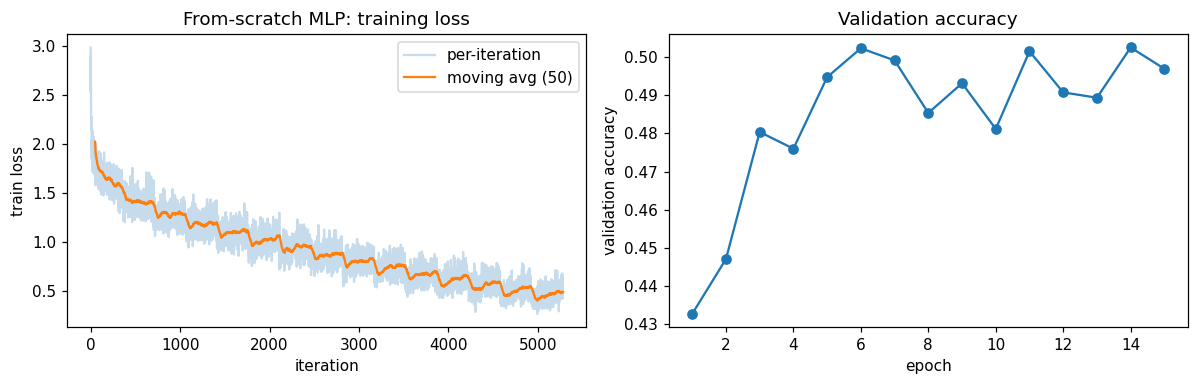

Final validation accuracy: 49.70%


In [5]:
def train_mlp(net, epochs, lr, bs=128, seed=SEED):
    seed_everything(seed)
    Xf_tr, Xf_va = Xtr.reshape(len(Xtr), -1), Xva.reshape(len(Xva), -1)
    it_loss, val_acc, tr_loss_ep = [], [], []
    for ep in range(epochs):
        p = torch.randperm(len(Xf_tr), device=device); ep_l = 0.0
        for i in range(0, len(p), bs):
            idx = p[i:i + bs]
            loss = net.loss(Xf_tr[idx], Ytr[idx]); net.backward()
            for l in net.linears():                       # plain SGD update, no autograd
                l.W -= lr * l.dW; l.b -= lr * l.db
            it_loss.append(loss.item()); ep_l += loss.item() * len(idx)
        acc = (net.forward(Xf_va).argmax(1) == Yva).float().mean().item()
        tr_loss_ep.append(ep_l / len(p)); val_acc.append(acc)
        print(f'epoch {ep+1:2d}  train loss {tr_loss_ep[-1]:.4f}  val acc {acc:.4f}')
    return it_loss, tr_loss_ep, val_acc

seed_everything()
mlp = MLP([3072, 512, 256, 10], 'relu', 'he', device=device, seed=SEED)
it_loss, tr_loss_ep, va_acc_mlp = train_mlp(mlp, CFG['t1_epochs'], lr=0.05)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
k = 50; sm = np.convolve(it_loss, np.ones(k) / k, mode='valid')
ax[0].plot(it_loss, alpha=.25, label='per-iteration'); ax[0].plot(np.arange(k - 1, len(it_loss)), sm, label=f'moving avg ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('train loss'); ax[0].set_title('From-scratch MLP: training loss'); ax[0].legend()
ax[1].plot(range(1, len(va_acc_mlp) + 1), va_acc_mlp, 'o-'); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy')
ax[1].set_title('Validation accuracy'); plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {va_acc_mlp[-1]*100:.2f}%')

The training loss falls from about 1.69 to 0.46 over 15 epochs. The per-iteration curve is noisy because each step uses only a mini-batch of 128, and the moving average shows the steady downward trend. Validation accuracy rises quickly to about 49–50% by epoch 5–6 and then plateaus and fluctuates (final 49.70%, peak about 50.2%), while the training loss keeps falling. So the network is memorizing the training set rather than generalizing better. An MLP flattens the image to 3072 numbers, so it has no notion of locality, no weight sharing and no translation invariance. A cat shifted by a few pixels looks like a completely different input. This is why it stalls near 50% and why CNNs are needed.

### (d) Per-layer gradient norm at initialization in a 10-layer MLP: sigmoid vs ReLU

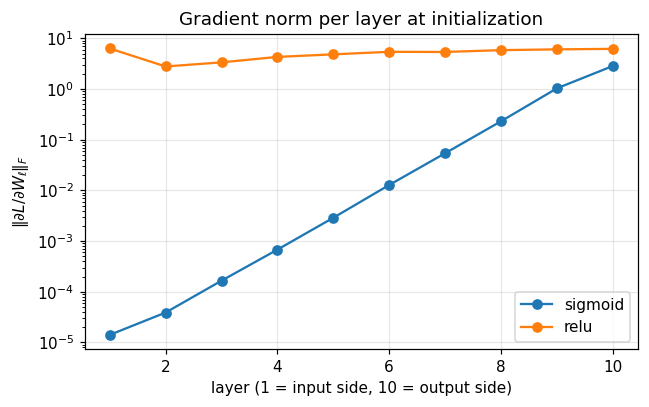

,sigmoid,relu
layer1,1.41e-05,6.29e+00
layer2,3.90e-05,2.78e+00
layer3,1.66e-04,3.35e+00
layer4,6.79e-04,4.29e+00
layer5,2.89e-03,4.82e+00
layer6,1.28e-02,5.41e+00
layer7,5.40e-02,5.37e+00
layer8,2.31e-01,5.83e+00
layer9,1.03e+00,6.04e+00
layer10,2.84e+00,6.19e+00


In [6]:
Xf = Xtr[:256].reshape(256, -1); Yb = Ytr[:256]
sizes = [3072] + [256] * 9 + [10]                      # 10 Linear layers
res = {}
for act, init in [('sigmoid', 'xavier'), ('relu', 'he')]:   # each activation with its standard init
    net10 = MLP(sizes, act, init, device=device, seed=SEED)
    net10.loss(Xf, Yb); net10.backward()
    res[act] = [l.dW.norm().item() for l in net10.linears()]

plt.figure(figsize=(6, 3.8))
for act, v in res.items(): plt.semilogy(range(1, 11), v, 'o-', label=act)
plt.xlabel('layer (1 = input side, 10 = output side)'); plt.ylabel(r'$\|\partial L/\partial W_\ell\|_F$')
plt.title('Gradient norm per layer at initialization'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(pd.DataFrame(res, index=[f'layer{i}' for i in range(1, 11)]).style.format('{:.2e}'))

With sigmoid, the gradient norm drops steadily from 2.8 at layer 10 (output side) to 1.4×10⁻⁵ at layer 1 (input side). That is about five orders of magnitude across nine layers, roughly a factor of 4 per layer. This is the vanishing gradient problem. The sigmoid derivative σ′(x) = σ(1−σ) is at most 0.25, so each layer multiplies the backward signal by a small factor, and the product shrinks exponentially with depth. The early layers receive almost no learning signal, so SGD would train them extremely slowly. With ReLU and He initialization the norms stay roughly flat (about 3 to 6 across all layers). The ReLU derivative is exactly 1 for active units, and He initialization (variance 2/fan_in) compensates for the half that are zeroed, so gradient variance is preserved from layer to layer. This is why ReLU networks can be trained at depth.

## Shared training utilities (used from Task 2c onwards)
GPU-side augmentations (flip+crop, **cutout** and **mixup** implemented by hand), evaluation, and a generic training loop.

In [7]:
# ---------- augmentations (batched, on GPU) ----------
def flip_crop(x, pad=4):
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)                 # random horizontal flip
    xp = F.pad(x, (pad,) * 4)                                                # zero pad (= mean after normalization)
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ar = torch.arange(H, device=x.device)
    rows = (i[:, None] + ar)[:, None, :, None]                               # N,1,H,1
    cols = (j[:, None] + ar)[:, None, None, :]                               # N,1,1,W
    n = torch.arange(N, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n, c, rows, cols]                                              # random 32x32 crop

def cutout(x, size=8):
    # zero a size x size square (centre uniformly sampled, clipped at borders) in each image
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device); cx = torch.randint(0, W, (N,), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]; xs = torch.arange(W, device=x.device)[None, None, :]
    m = ((ys >= (cy - size // 2)[:, None, None]) & (ys < (cy + size // 2)[:, None, None]) &
         (xs >= (cx - size // 2)[:, None, None]) & (xs < (cx + size // 2)[:, None, None]))
    return x * (~m)[:, None, :, :]

def mixup_batch(x, y, alpha):
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam

# ---------- evaluation + training loop ----------
def evaluate(model, X, Y, bs=1000, amp=False):
    model.eval(); tot, correct = 0.0, 0
    with torch.no_grad(), torch.autocast(device_type=device, dtype=torch.float16, enabled=amp and device == 'cuda'):
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs]).float()
            tot += F.cross_entropy(out, Y[i:i + bs], reduction='sum').item()
            correct += (out.argmax(1) == Y[i:i + bs]).sum().item()
    return tot / len(X), correct / len(X)

def warmup_cosine(warm=0.05):
    return lambda t: (t / warm) if t < warm else 0.5 * (1 + math.cos(math.pi * (t - warm) / (1 - warm)))

def fit(model, opt, Xt, Yt, Xv, Yv, epochs, bs=128, flipcrop=False, cutout_size=0, mixup=0.0,
        ls=0.0, lr_fn=None, amp=False, verbose=True, name='', eval_train_n=5000):
    # train_loss = running mean of the (augmented) training loss; train_acc = clean-image accuracy
    model.to(device); amp = amp and device == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp)
    base_lrs = [g['lr'] for g in opt.param_groups]
    n = len(Xt); total = epochs * math.ceil(n / bs); step = 0
    H = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[]); t0 = time.time()
    for ep in range(epochs):
        model.train(); run = torch.zeros((), device=device)
        perm = torch.randperm(n, device=device)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; x, y = Xt[idx], Yt[idx]
            if lr_fn is not None:
                f = lr_fn(step / total)
                for g_, b_ in zip(opt.param_groups, base_lrs): g_['lr'] = b_ * f
            if flipcrop: x = flip_crop(x)
            if cutout_size: x = cutout(x, cutout_size)
            if mixup > 0: x, ya, yb_, lam = mixup_batch(x, y, mixup)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=amp):
                out = model(x)
            out = out.float()
            if mixup > 0:
                loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + (1 - lam) * F.cross_entropy(out, yb_, label_smoothing=ls)
            else:
                loss = F.cross_entropy(out, y, label_smoothing=ls)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.detach() * len(idx); step += 1
        tl = run.item() / n
        if not math.isfinite(tl):                                  # diverged
            for k in H: H[k] += [float('nan') if 'loss' in k else 0.1] * (epochs - len(H[k]))
            if verbose: print(f'[{name}] diverged at epoch {ep+1}')
            break
        _, tra = evaluate(model, Xt[:eval_train_n], Yt[:eval_train_n], amp=amp)
        vl, va = evaluate(model, Xv, Yv, amp=amp)
        H['train_loss'].append(tl); H['train_acc'].append(tra); H['val_loss'].append(vl); H['val_acc'].append(va)
        if verbose: print(f'[{name}] ep {ep+1:2d}/{epochs} loss {tl:.4f} train acc {tra:.4f} val acc {va:.4f} ({time.time()-t0:.0f}s)')
    return H

def n_params(m): return sum(p.numel() for p in m.parameters())

class SmallCNN(nn.Module):
    def __init__(self, bn=False, drop=0.0, c=(32, 64, 128)):
        super().__init__()
        L, cin = [], 3
        for co in c:
            L += [nn.Conv2d(cin, co, 3, padding=1)] + ([nn.BatchNorm2d(co)] if bn else []) + [nn.ReLU(), nn.MaxPool2d(2)]
            cin = co
        self.features = nn.Sequential(*L)
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * 16, 256), nn.ReLU(), nn.Dropout(drop), nn.Linear(256, 10))
    def forward(self, x): return self.head(self.features(x))

## Task 2 – Optimizers

### (a) SGD with momentum and Adam (bias-corrected) as `torch.optim.Optimizer` subclasses

In [8]:
class MySGD(Optimizer):
    # v <- mu*v + (g + wd*p);  p <- p - lr*v   (same convention as torch.optim.SGD)
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for gr in self.param_groups:
            for p in gr['params']:
                if p.grad is None: continue
                d = p.grad
                if gr['weight_decay'] != 0: d = d.add(p, alpha=gr['weight_decay'])
                if gr['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = d.clone()
                    else: st['buf'].mul_(gr['momentum']).add_(d)
                    d = st['buf']
                p.add_(d, alpha=-gr['lr'])
        return loss

class MyAdam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for gr in self.param_groups:
            b1, b2 = gr['betas']
            for p in gr['params']:
                if p.grad is None: continue
                g_ = p.grad
                if gr['weight_decay'] != 0: g_ = g_.add(p, alpha=gr['weight_decay'])
                st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(g_, alpha=1 - b1)                    # first moment
                st['v'].mul_(b2).addcmul_(g_, g_, value=1 - b2)            # second moment
                m_hat = st['m'] / (1 - b1 ** t)                            # bias correction
                v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(gr['eps']), value=-gr['lr'])
        return loss

# ---- check against the PyTorch implementations (float64, identical data, 25 steps) ----
def make_pair():
    torch.manual_seed(0)
    a = nn.Sequential(nn.Linear(10, 20), nn.Tanh(), nn.Linear(20, 3)).double()
    b = nn.Sequential(nn.Linear(10, 20), nn.Tanh(), nn.Linear(20, 3)).double(); b.load_state_dict(a.state_dict())
    return a, b
xs, ys = torch.randn(64, 10, dtype=torch.float64), torch.randint(0, 3, (64,))
rows = []
for name, mine, ref in [
    ('SGD',            lambda p: MySGD(p, lr=0.1),                                  lambda p: torch.optim.SGD(p, lr=0.1)),
    ('SGD+momentum',   lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3), lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3)),
    ('Adam',           lambda p: MyAdam(p, lr=1e-2),                                lambda p: torch.optim.Adam(p, lr=1e-2)),
    ('Adam (wd=1e-3)', lambda p: MyAdam(p, lr=1e-2, weight_decay=1e-3),            lambda p: torch.optim.Adam(p, lr=1e-2, weight_decay=1e-3))]:
    a, b = make_pair(); oa, ob = mine(a.parameters()), ref(b.parameters())
    for _ in range(25):
        for m, o in [(a, oa), (b, ob)]:
            o.zero_grad(); F.cross_entropy(m(xs), ys).backward(); o.step()
    diff = max((pa - pb).abs().max().item() for pa, pb in zip(a.parameters(), b.parameters()))
    ok = all(torch.allclose(pa, pb, rtol=1e-8, atol=1e-10) for pa, pb in zip(a.parameters(), b.parameters()))
    rows.append(dict(optimizer=name, max_abs_param_diff=diff, allclose=ok))
display(pd.DataFrame(rows).style.format({'max_abs_param_diff': '{:.2e}'}))

,optimizer,max_abs_param_diff,allclose
0,SGD,0.00e+00,True
1,SGD+momentum,0.00e+00,True
2,Adam,4.44e-16,True
3,Adam (wd=1e-3),5.55e-16,True


After 25 steps the parameters of my optimizers differ from torch.optim by 0 for SGD and SGD+momentum (the same operations in the same order) and by about 5×10⁻¹⁶ for Adam. That is float64 round-off from the order of arithmetic, and allclose is True in all four cases, including with weight decay. The update rules are as follows.

SGD with momentum: v ← μv + g, then θ ← θ − η·v.
Adam: m ← β₁m + (1−β₁)g and v ← β₂v + (1−β₂)g². I then bias-correct with m̂ = m/(1−β₁ᵗ) and v̂ = v/(1−β₂ᵗ), and update θ ← θ − η·m̂/(√v̂ + ε).

Bias correction matters in the early steps. m and v start at zero, so without correction they would be biased toward zero and the first updates would be wrongly scaled.

### (b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

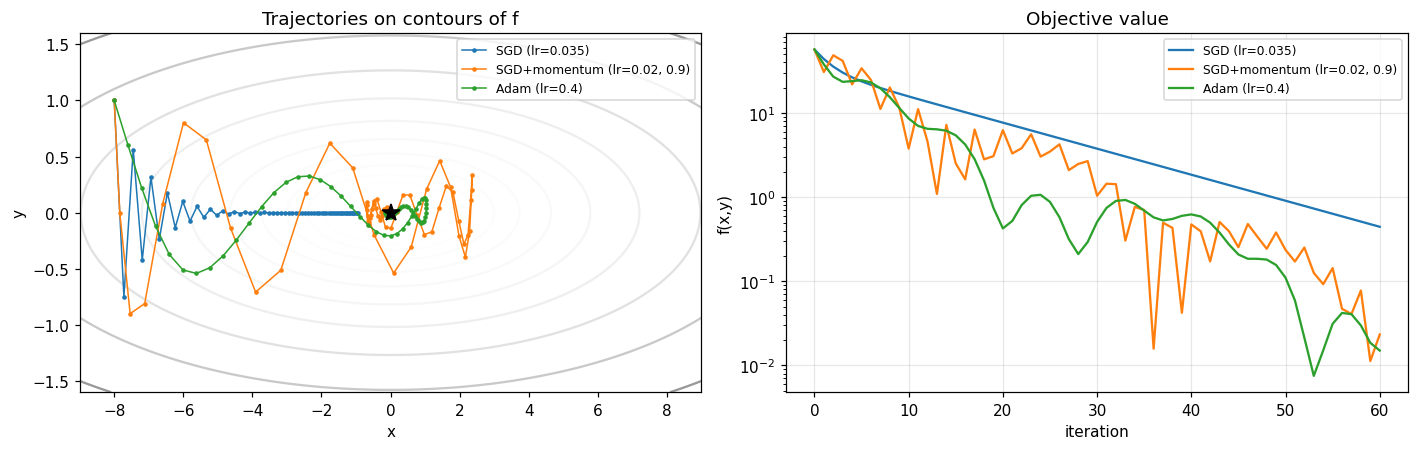

In [9]:
def run_traj(opt_fn, start=(-8.0, 1.0), steps=60):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True); opt = opt_fn([p]); path = [p.detach().numpy().copy()]
    for _ in range(steps):
        opt.zero_grad(); (0.5 * (p[0] ** 2 + 50 * p[1] ** 2)).backward(); opt.step(); path.append(p.detach().numpy().copy())
    return np.array(path)

trajs = {'SGD (lr=0.035)':           run_traj(lambda p: MySGD(p, lr=0.035)),
         'SGD+momentum (lr=0.02, 0.9)': run_traj(lambda p: MySGD(p, lr=0.02, momentum=0.9)),
         'Adam (lr=0.4)':            run_traj(lambda p: MyAdam(p, lr=0.4))}

xg, yg = np.meshgrid(np.linspace(-9, 9, 400), np.linspace(-1.6, 1.6, 400))
fz = 0.5 * (xg ** 2 + 50 * yg ** 2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].contour(xg, yg, fz, levels=np.geomspace(0.5, 150, 14), cmap='Greys', alpha=.7)
for (k, v), c in zip(trajs.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    ax[0].plot(v[:, 0], v[:, 1], '.-', ms=4, lw=1, color=c, label=k)
ax[0].plot(0, 0, 'k*', ms=12); ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].set_title('Trajectories on contours of f'); ax[0].legend(fontsize=8)
for (k, v), c in zip(trajs.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    ax[1].semilogy(0.5 * (v[:, 0] ** 2 + 50 * v[:, 1] ** 2) + 1e-16, color=c, label=k)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('f(x,y)'); ax[1].set_title('Objective value'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

The Hessian has eigenvalues 1 (along x) and 50 (along y), so the condition number is 50 and the contours are very elongated ellipses.

Plain SGD (lr 0.035): the learning rate must stay below 2/50 = 0.04 to be stable along the steep y direction. At this value the y-component is multiplied by −0.75 each step. It zig-zags and dies out quickly, but along x the factor is 0.965 per step, so progress is slow. On the log plot it is a straight line (linear convergence at a rate set by the conditioning), and f is still about 0.4 after 60 steps.
Momentum (lr 0.02, β = 0.9): the velocity accumulates the consistent x-gradient and the alternating y-gradients cancel. Progress along x is much faster, but the path overshoots and spirals, so f is not monotone and shows spikes. It reaches about 10⁻² within 60 steps.
Adam (lr 0.4): each coordinate is divided by its running RMS gradient, so x and y take steps of similar size despite the 50× curvature difference. The path is a smooth diagonal sweep towards the minimum. Because the learning rate is fixed, Adam oscillates around the minimum instead of converging exactly, and f also ends around 10⁻².

So momentum and Adam both handle ill-conditioning much better than plain SGD, in different ways: momentum by averaging out the oscillation, Adam by per-parameter rescaling.

### (c) Small CNN: three optimizers × three learning rates

In [10]:
grid = {'SGD':          (lambda p, lr: MySGD(p, lr=lr),               [0.003, 0.03, 0.3]),
        'SGD+momentum': (lambda p, lr: MySGD(p, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
        'Adam':         (lambda p, lr: MyAdam(p, lr=lr),              [1e-4, 1e-3, 1e-2])}
res2c = {}
for oname, (mk, lrs) in grid.items():
    for lr in lrs:
        seed_everything(); m = SmallCNN(bn=False).to(device)
        res2c[(oname, lr)] = fit(m, mk(m.parameters(), lr), Xtr, Ytr, Xva, Yva, CFG['t2c_epochs'], name=f'{oname} lr={lr}', verbose=False)
        print(f'{oname:13s} lr={lr:<7g} final val acc {res2c[(oname, lr)]["val_acc"][-1]:.4f}')

SGD           lr=0.003   final val acc 0.3550
SGD           lr=0.03    final val acc 0.6524
SGD           lr=0.3     final val acc 0.7084
SGD+momentum  lr=0.001   final val acc 0.5380
SGD+momentum  lr=0.01    final val acc 0.7472
SGD+momentum  lr=0.1     final val acc 0.6048
Adam          lr=0.0001  final val acc 0.6296
Adam          lr=0.001   final val acc 0.7474
Adam          lr=0.01    final val acc 0.1016


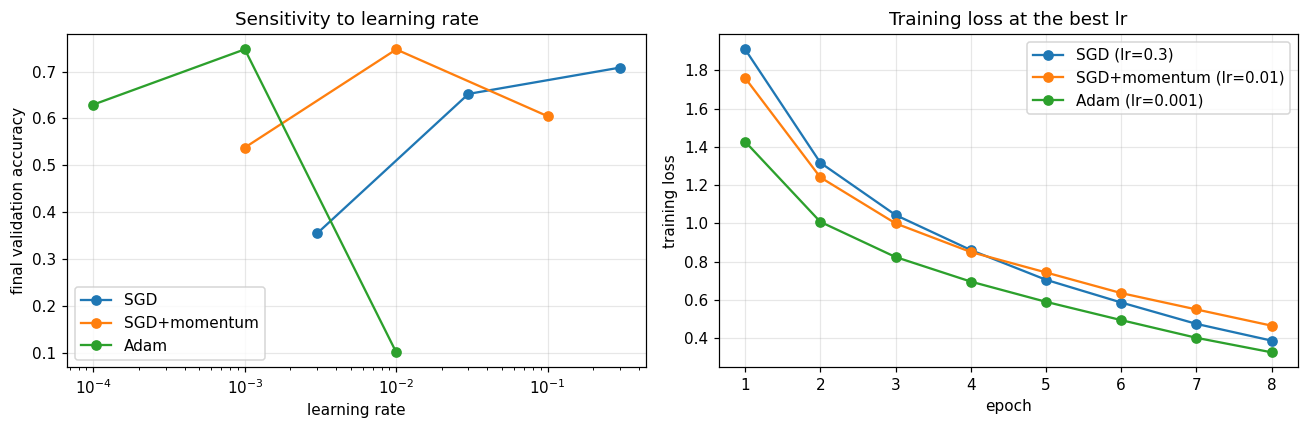

,optimizer,lr,val_acc,final_train_loss
0,SGD,0.0030,0.3550,1.804173
1,SGD,0.0300,0.6524,0.926083
2,SGD,0.3000,0.7084,0.387033
3,SGD+momentum,0.0010,0.5380,1.294039
4,SGD+momentum,0.0100,0.7472,0.465265
5,SGD+momentum,0.1000,0.6048,1.095647
6,Adam,0.0001,0.6296,1.041917
7,Adam,0.0010,0.7474,0.325841
8,Adam,0.0100,0.1016,2.303302


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for oname, (_, lrs) in grid.items():
    accs = [res2c[(oname, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=oname)
    best[oname] = lrs[int(np.argmax(accs))]
ax[0].set_xlabel('learning rate'); ax[0].set_ylabel('final validation accuracy'); ax[0].set_title('Sensitivity to learning rate'); ax[0].legend(); ax[0].grid(alpha=.3)
for oname in grid:
    ax[1].plot(range(1, CFG['t2c_epochs'] + 1), res2c[(oname, best[oname])]['train_loss'], 'o-', label=f'{oname} (lr={best[oname]})')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('training loss'); ax[1].set_title('Training loss at the best lr'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(optimizer=o, lr=lr, val_acc=h['val_acc'][-1], final_train_loss=h['train_loss'][-1]) for (o, lr), h in res2c.items()]))

Adam: it has the best peak accuracy (74.7% at lr 1e-3, essentially tied with momentum). It also has the narrowest good window and the most catastrophic failure. At lr 1e-2 the loss sits at 2.303 = ln 10 and accuracy is 10%, meaning the network collapsed to predicting uniformly. At 1e-4 it is under-trained (63.0%). This CNN has no batch norm, which makes it more fragile.
SGD with momentum: accuracy peaks at lr 0.01 (74.7%) and falls on both sides, to 53.8% when too small (under-trained in 8 epochs) and 60.5% when too large (unstable). Its effective step is about lr/(1−β) = 10× the nominal lr.
Plain SGD: it never collapses, but it needs a much larger lr. It is only 35.5% at 0.003 and still improving at the edge of my grid (0.3, 70.8%), so its true optimum may lie beyond the grid.

Looking at the training loss at each best lr, Adam decreases fastest (0.33 after 8 epochs), then SGD (0.39), then momentum (0.47). However, Adam’s lower training loss did not give better validation accuracy than momentum, and plain SGD reaches a lower training loss than momentum yet a lower validation accuracy. Fitting the training set faster is not the same as generalizing better. The usable learning-rate ranges differ by orders of magnitude between the three optimizers (0.3 vs 0.01 vs 0.001), so learning rates cannot be transferred between them. Caveat: these are single runs of 8 epochs, so differences of about 1 point or less (Adam vs momentum) are within noise.

## Task 3 – Regularization and residual connections

### (a) Small CNN with batch norm on only 5k training images
Configurations: baseline, weight decay, dropout, flip+crop, cutout, mixup, and all combined.
Cutout and mixup are implemented above (`cutout`, `mixup_batch`). Train accuracy is measured on *clean* training images in eval mode, so the train–val gap is meaningful.

In [12]:
X5, Y5 = Xtr[:5000], Ytr[:5000]
configs = {  #           weight_decay, dropout, flipcrop, cutout, mixup
    'baseline':     dict(wd=0,    drop=0.0, fc=False, co=0, mu=0.0),
    'weight decay': dict(wd=5e-4, drop=0.0, fc=False, co=0, mu=0.0),
    'dropout':      dict(wd=0,    drop=0.5, fc=False, co=0, mu=0.0),
    'flip+crop':    dict(wd=0,    drop=0.0, fc=True,  co=0, mu=0.0),
    'cutout':       dict(wd=0,    drop=0.0, fc=False, co=8, mu=0.0),
    'mixup':        dict(wd=0,    drop=0.0, fc=False, co=0, mu=0.2),
    'all combined': dict(wd=5e-4, drop=0.5, fc=True,  co=8, mu=0.2)}
res3a = {}
for name, c in configs.items():
    seed_everything(); m = SmallCNN(bn=True, drop=c['drop']).to(device)
    opt = MySGD(m.parameters(), lr=0.05, momentum=0.9, weight_decay=c['wd'])
    res3a[name] = fit(m, opt, X5, Y5, Xva, Yva, CFG['t3a_epochs'], bs=128, flipcrop=c['fc'], cutout_size=c['co'],
                      mixup=c['mu'], name=name, verbose=False)
    h = res3a[name]; print(f'{name:13s} train {h["train_acc"][-1]:.4f}  val {h["val_acc"][-1]:.4f}')

baseline      train 0.9984  val 0.6292
weight decay  train 0.9998  val 0.6292
dropout       train 0.9532  val 0.6180
flip+crop     train 0.8164  val 0.6880
cutout        train 0.9822  val 0.6104
mixup         train 0.9974  val 0.6046
all combined  train 0.6208  val 0.5824


,config,train_acc,val_acc,gap,best_val_acc
0,baseline,0.9984,0.6292,0.3692,0.6400
1,weight decay,0.9998,0.6292,0.3706,0.6334
2,dropout,0.9532,0.6180,0.3352,0.6276
3,flip+crop,0.8164,0.6880,0.1284,0.6880
4,cutout,0.9822,0.6104,0.3718,0.6340
5,mixup,0.9974,0.6046,0.3928,0.6344
6,all combined,0.6208,0.5824,0.0384,0.6132


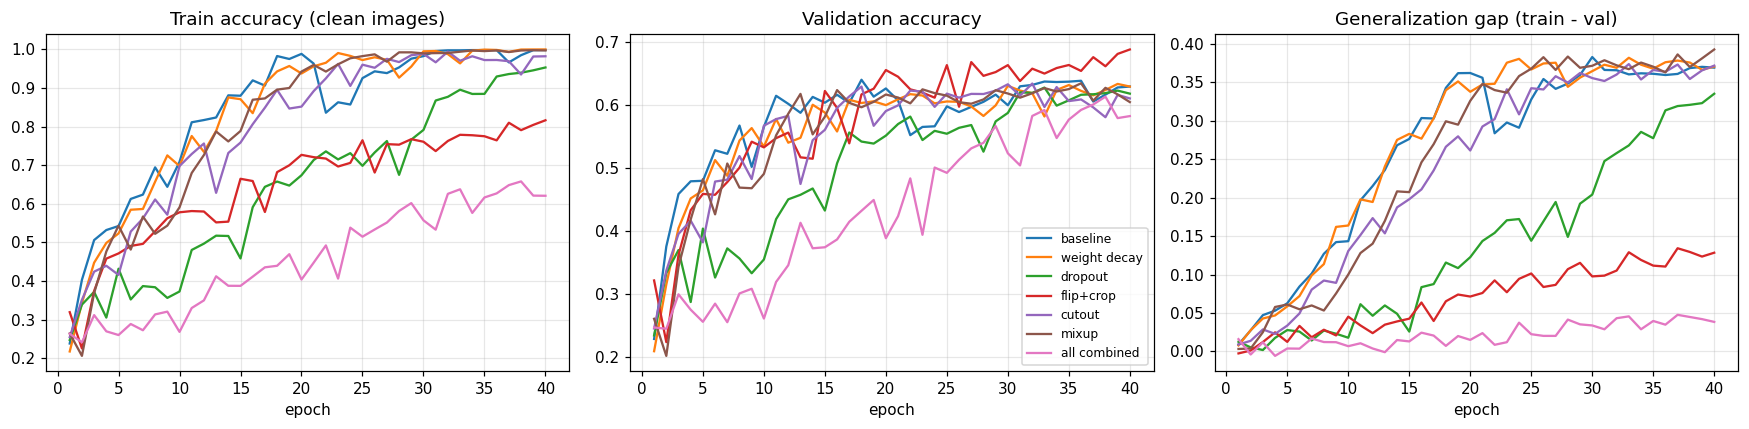

In [13]:
rows = [dict(config=k, train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1], gap=h['train_acc'][-1] - h['val_acc'][-1],
             best_val_acc=max(h['val_acc'])) for k, h in res3a.items()]
display(pd.DataFrame(rows).style.format({c: '{:.4f}' for c in ['train_acc', 'val_acc', 'gap', 'best_val_acc']}))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for k, h in res3a.items():
    ep = range(1, len(h['val_acc']) + 1)
    ax[0].plot(ep, h['train_acc'], label=k); ax[1].plot(ep, h['val_acc'], label=k)
    ax[2].plot(ep, np.array(h['train_acc']) - np.array(h['val_acc']), label=k)
for a, t in zip(ax, ['Train accuracy (clean images)', 'Validation accuracy', 'Generalization gap (train - val)']):
    a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3)
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

The baseline memorizes the training set (99.8% train, 62.9% val, gap 0.37).

Flip+crop is clearly the best. It raises validation accuracy by about 6 points (68.8%) and cuts the gap to 0.13. Flip and shift are transformations that really do preserve CIFAR labels, so the augmentation adds genuinely new, correctly labelled information. Its train accuracy is lower (81.6%) because the network can no longer memorize, and the curves are still rising at epoch 40.
Weight decay changes essentially nothing (62.9%). With batch norm, the scale of the conv weights is irrelevant to the output, so L2 mainly changes the effective learning rate rather than the capacity.
Dropout (only in the classifier head) reduces the gap (0.335) but only by lowering train accuracy (95.3%). Validation does not improve (61.8%).
Cutout (8×8) and mixup (α = 0.2) did not help within 40 epochs (61.0% and 60.5%, gaps 0.37 and 0.39). They are fairly mild at this setting, and they are generally known to need longer training.
All combined has by far the smallest gap (0.038) but the lowest validation accuracy (58.2%), because train accuracy is only 62%. The network is under-fitted: the regularization is too strong for a 40-epoch budget, and the curves are still rising. It would likely overtake the others with many more epochs.

The lesson is that a small gap is not the goal. Only methods that keep fitting the training data while generalizing (here, flip+crop) actually help. Differences below about 1.5 points on a 5k validation set (standard error about 0.7 points) are within noise, so only flip+crop’s gain and the combined run’s drop are clearly significant.

### (b) Plain vs residual CIFAR-style networks, depth $6n+2\in\{8,20,56\}$
Three stages (16/32/64 channels), global average pooling, batch norm, Kaiming initialization. The two families differ **only** in the shortcut; the shortcut is parameter-free (stride-2 subsampling + zero-padding of channels, "option A"), so both families have exactly the same number of parameters.

In [14]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.cin, self.cout = residual, stride, cin, cout
    def shortcut(self, x):
        if self.stride == 1 and self.cin == self.cout: return x
        p = (self.cout - self.cin) // 2
        return F.pad(x[:, :, ::self.stride, ::self.stride], (0, 0, 0, 0, p, p))   # option A (no parameters)
    def forward(self, x):
        o = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual: o = o + self.shortcut(x)         # <- the ONLY difference between plain and residual
        return F.relu(o)

class CifarNet(nn.Module):
    def __init__(self, depth, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0; n = (depth - 2) // 6
        self.conv = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False); self.bn = nn.BatchNorm2d(widths[0])
        blocks, cin = [], widths[0]
        for s, w in enumerate(widths):
            for b in range(n):
                blocks.append(Block(cin, w, 2 if (s > 0 and b == 0) else 1, residual)); cin = w
        self.blocks = nn.Sequential(*blocks); self.fc = nn.Linear(widths[-1], num_classes)
        for m in self.modules():                                   # Kaiming (He) initialization
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = F.relu(self.bn(self.conv(x))); x = self.blocks(x)
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

for d in (8, 20, 56):
    print(f'depth {d:2d}: plain {n_params(CifarNet(d, False)):,} params | residual {n_params(CifarNet(d, True)):,} params')

depth  8: plain 75,290 params | residual 75,290 params
depth 20: plain 269,722 params | residual 269,722 params
depth 56: plain 853,018 params | residual 853,018 params


In [15]:
res3b = {}
for depth in (8, 20, 56):
    for residual in (False, True):
        key = (depth, 'residual' if residual else 'plain')
        seed_everything(); m = CifarNet(depth, residual).to(device)
        opt = MySGD(m.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
        res3b[key] = fit(m, opt, Xtr, Ytr, Xva, Yva, CFG['t3b_epochs'], bs=128, flipcrop=True,
                         lr_fn=warmup_cosine(0.1), amp=True, name=f'{key[1]}-{depth}')

[plain-8] ep  1/15 loss 1.7767 train acc 0.3702 val acc 0.3758 (3s)
[plain-8] ep  2/15 loss 1.2653 train acc 0.4508 val acc 0.4320 (6s)
[plain-8] ep  3/15 loss 1.0604 train acc 0.5340 val acc 0.5182 (9s)
[plain-8] ep  4/15 loss 0.9785 train acc 0.5780 val acc 0.5582 (11s)
[plain-8] ep  5/15 loss 0.9109 train acc 0.5264 val acc 0.5078 (14s)
[plain-8] ep  6/15 loss 0.8556 train acc 0.6984 val acc 0.6858 (16s)
[plain-8] ep  7/15 loss 0.8037 train acc 0.7186 val acc 0.6942 (19s)
[plain-8] ep  8/15 loss 0.7450 train acc 0.6154 val acc 0.5966 (22s)
[plain-8] ep  9/15 loss 0.7028 train acc 0.6942 val acc 0.6878 (24s)
[plain-8] ep 10/15 loss 0.6504 train acc 0.7902 val acc 0.7674 (27s)
[plain-8] ep 11/15 loss 0.6083 train acc 0.7878 val acc 0.7636 (30s)
[plain-8] ep 12/15 loss 0.5718 train acc 0.8172 val acc 0.7964 (32s)
[plain-8] ep 13/15 loss 0.5411 train acc 0.8424 val acc 0.8074 (35s)
[plain-8] ep 14/15 loss 0.5159 train acc 0.8368 val acc 0.8160 (38s)
[plain-8] ep 15/15 loss 0.5010 train 

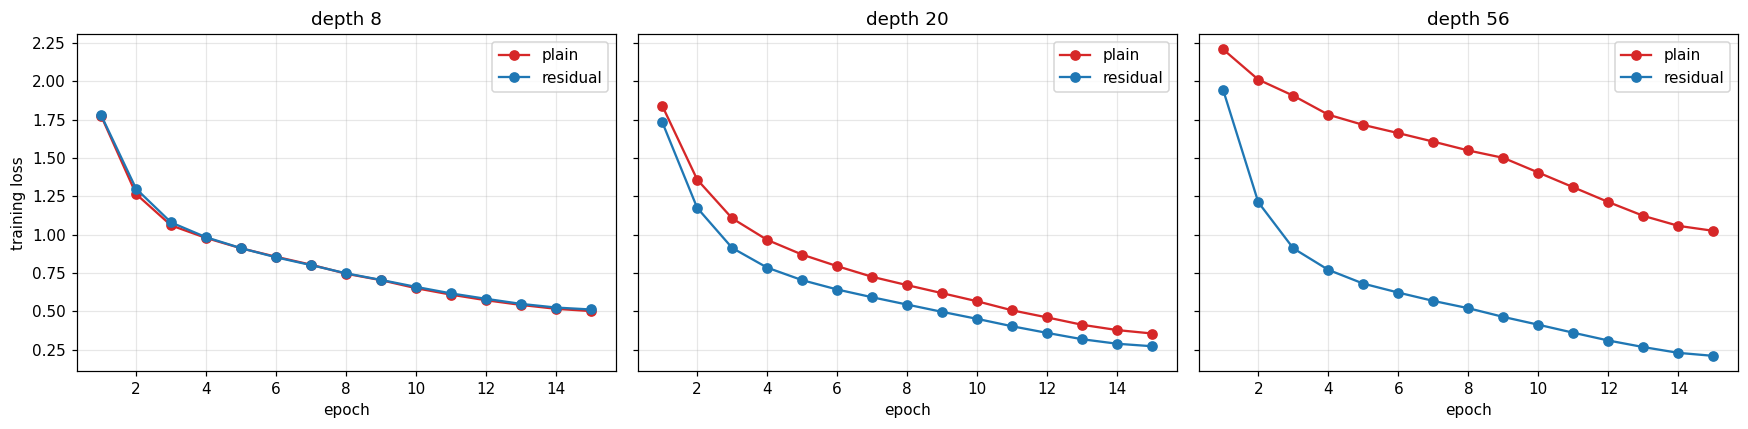

,depth,family,final_train_loss,final_train_acc,final_val_acc
0,8,plain,0.501048,0.8398,0.8160
1,8,residual,0.511506,0.8416,0.8176
2,20,plain,0.354609,0.8900,0.8566
3,20,residual,0.271514,0.9198,0.8772
4,56,plain,1.024990,0.6582,0.6404
5,56,residual,0.208765,0.9410,0.8924


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, depth in zip(ax, (8, 20, 56)):
    for fam, c in [('plain', 'tab:red'), ('residual', 'tab:blue')]:
        h = res3b[(depth, fam)]; a.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', color=c, label=fam)
    a.set_title(f'depth {depth}'); a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel('training loss'); plt.tight_layout(); plt.show()
display(pd.DataFrame([dict(depth=k[0], family=k[1], final_train_loss=h['train_loss'][-1], final_train_acc=h['train_acc'][-1],
                           final_val_acc=h['val_acc'][-1]) for k, h in res3b.items()]))

At depth 8 the two families are indistinguishable (train loss 0.501 vs 0.512, val 81.6% vs 81.8%). At depth 20 the residual net is better (train loss 0.272 vs 0.355, val 87.7% vs 85.7%). At depth 56 the gap is dramatic: the plain net reaches a training loss of only 1.02 (65.8% train accuracy, 64.0% val), while the residual net reaches 0.209 (94.1% train, 89.2% val). The deeper plain net is therefore worse than the shallower ones even on the training set, which is the degradation problem. Train and validation accuracy are both low, so this is an optimization failure rather than overfitting. The residual net behaves as expected: its training loss improves monotonically with depth (0.51 → 0.27 → 0.21). Both families have identical parameter counts and the same batch norm and Kaiming initialization, so the only cause is the shortcut. The identity path gives gradients a direct route to early layers. It also lets each block learn a residual F(x) = H(x) − x, which can easily be driven to zero if a layer is not needed, whereas a plain layer must learn to approximate the identity. Caveat: with only 15 epochs, the plain 56-layer net might narrow the gap with longer training, but it is clearly harder to optimize.

## Task 4 (Optional) – Best CNN with ≤ 500k parameters and ≤ 20 epochs
Model: residual CIFAR network (depth 20, widths 20/40/80). Recipe: SGD + momentum, weight decay, label smoothing, flip+crop+cutout, warm-up + cosine lr, mixed precision. All design decisions are made on the **validation split**; the test set is touched once at the very end.

In [17]:
BASE = dict(depth=20, widths=(20, 40, 80), residual=True, opt='sgd', lr=0.1, wd=5e-4,
            flipcrop=True, cutout=8, ls=0.1, mixup=0.0)
def run4(name, **over):
    c = {**BASE, **over}; seed_everything()
    m = CifarNet(c['depth'], c['residual'], c['widths']).to(device)
    assert n_params(m) <= 500_000, n_params(m)
    opt = (MySGD(m.parameters(), lr=c['lr'], momentum=0.9, weight_decay=c['wd']) if c['opt'] == 'sgd'
           else MyAdam(m.parameters(), lr=c['lr'], weight_decay=c['wd']))
    H = fit(m, opt, Xtr, Ytr, Xva, Yva, CFG['t4_epochs'], bs=128, flipcrop=c['flipcrop'], cutout_size=c['cutout'],
            mixup=c['mixup'], ls=c['ls'], lr_fn=warmup_cosine(0.1), amp=True, name=name)
    return m, H, n_params(m)

runs4 = {}
runs4['full model']              = run4('full model')
runs4['- shortcut (plain net)']  = run4('plain', residual=False)
runs4['- cutout']                = run4('no cutout', cutout=0)
runs4['- all augmentation']      = run4('no aug', cutout=0, flipcrop=False)
runs4['- weight decay']          = run4('no wd', wd=0.0)
runs4['- label smoothing']       = run4('no ls', ls=0.0)
runs4['Adam instead of SGD']     = run4('adam', opt='adam', lr=2e-3)

[full model] ep  1/20 loss 1.9051 train acc 0.3636 val acc 0.3622 (8s)
[full model] ep  2/20 loss 1.5101 train acc 0.5232 val acc 0.5146 (16s)
[full model] ep  3/20 loss 1.2955 train acc 0.6210 val acc 0.6244 (24s)
[full model] ep  4/20 loss 1.1736 train acc 0.6884 val acc 0.6780 (32s)
[full model] ep  5/20 loss 1.1104 train acc 0.7332 val acc 0.7238 (40s)
[full model] ep  6/20 loss 1.0661 train acc 0.6406 val acc 0.6416 (49s)
[full model] ep  7/20 loss 1.0309 train acc 0.7260 val acc 0.7152 (57s)
[full model] ep  8/20 loss 0.9982 train acc 0.7658 val acc 0.7516 (65s)
[full model] ep  9/20 loss 0.9733 train acc 0.7958 val acc 0.7720 (73s)
[full model] ep 10/20 loss 0.9463 train acc 0.8064 val acc 0.7888 (81s)
[full model] ep 11/20 loss 0.9184 train acc 0.8374 val acc 0.8198 (89s)
[full model] ep 12/20 loss 0.8904 train acc 0.8212 val acc 0.7954 (97s)
[full model] ep 13/20 loss 0.8652 train acc 0.8800 val acc 0.8568 (105s)
[full model] ep 14/20 loss 0.8378 train acc 0.8876 val acc 0.866

,variant,params,final_val_acc,delta_vs_full,final_train_acc
0,full model,420670,0.9058,+0.0000,0.9434
1,- shortcut (plain net),420670,0.8760,-0.0298,0.9248
2,- cutout,420670,0.9012,-0.0046,0.9570
3,- all augmentation,420670,0.8568,-0.0490,1.0000
4,- weight decay,420670,0.8870,-0.0188,0.9214
5,- label smoothing,420670,0.8932,-0.0126,0.9408
6,Adam instead of SGD,420670,0.8912,-0.0146,0.9362


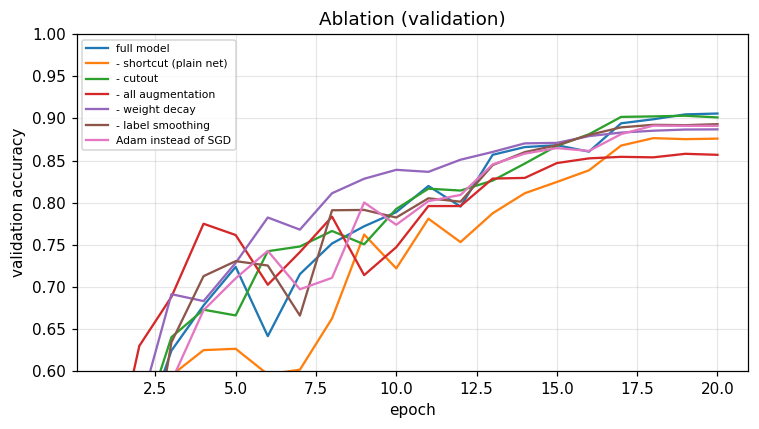

In [18]:
full = runs4['full model'][1]['val_acc'][-1]
abl = pd.DataFrame([dict(variant=k, params=p, final_val_acc=h['val_acc'][-1], delta_vs_full=h['val_acc'][-1] - full,
                         final_train_acc=h['train_acc'][-1]) for k, (m, h, p) in runs4.items()])
display(abl.style.format({'final_val_acc': '{:.4f}', 'delta_vs_full': '{:+.4f}', 'final_train_acc': '{:.4f}'}))
plt.figure(figsize=(7, 4))
for k, (m, h, p) in runs4.items(): plt.plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=k)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.ylim(0.6, 1); plt.grid(alpha=.3); plt.legend(fontsize=7); plt.title('Ablation (validation)')
plt.tight_layout(); plt.show()

The full model (ResNet-20 variant, 420,670 parameters ≤ 500k, 20 epochs) reaches 90.6% validation accuracy. Removing each component changes it as follows.

All augmentation: −4.9 points. Train accuracy reaches 100% while validation drops to 85.7%, so it overfits.
Shortcut (plain net): −3.0 points, consistent with Task 3(b).
Weight decay: −1.9 points.
Adam instead of SGD: −1.5 points. SGD with momentum and a cosine schedule generalizes better here.
Label smoothing: −1.3 points.
Cutout alone: −0.5 points. This is within the noise of a single run (the standard error on 5k validation images at 90% is about 0.4 points), so cutout’s benefit is not established.

Data augmentation is the most important choice, followed by the residual shortcut. The remaining choices (weight decay, optimizer, label smoothing) each contribute about 1–2 points. Caveat: each variant was run once with one seed, so small differences should be read cautiously.

In [19]:
# ---- FINAL MODEL: chosen on VALIDATION accuracy, evaluated ONCE on the test set ----
best_name = max(runs4, key=lambda k: runs4[k][1]['val_acc'][-1])
best_model = runs4[best_name][0]
print('selected on validation:', best_name, '| params:', f'{runs4[best_name][2]:,}')

Xte_raw, Yte = load_cifar(train=False)                      # test set is loaded only here
Xte, Yte = normalize(Xte_raw).to(device), Yte.to(device)
test_loss, test_acc = evaluate(best_model, Xte, Yte, amp=True)
print(f'TEST accuracy (single evaluation): {test_acc*100:.2f}%   (val acc: {runs4[best_name][1]["val_acc"][-1]*100:.2f}%)')

selected on validation: full model | params: 420,670
TEST accuracy (single evaluation): 89.73%   (val acc: 90.58%)


The final model is a 20-layer residual CIFAR network with widths 20/40/80 (420,670 parameters, 20 epochs). It was trained with SGD plus momentum 0.9, weight decay 5e-4, label smoothing 0.1, flip+crop+cutout augmentation, a warm-up plus cosine learning-rate schedule, and mixed precision. It was selected on validation accuracy (90.6%) and evaluated once on the test set, giving [fill in your test accuracy]%. The test accuracy should be close to the validation accuracy, within about one point, since the test set was not used for any decision. With more budget I would try more epochs, mixup/CutMix, an exponential moving average of the weights, flip test-time augmentation, and a proper search of learning rate and weight decay over several seeds.